In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from PIL import Image

In [2]:
data = pd.read_csv("data.csv")

In [7]:
data.condition.unique(), data.columns

(<StringArray>
 ['flat_ground', 'terrain_blind', 'terrain_observed', 'terrain_periodic']
 Length: 4, dtype: str,
 Index(['condition', 'height', 'irregularity', 'observed', 'delay_k',
        'delay_ms', 'seed_pair', 'impl', 'wandb_id', 'wandb_name', 'state',
        'created_at', 'budget', 'git_commit', 'dirty', 'gpu', 'reward_source',
        'reward', 'reward_n', 'late_gain', 'late_slope', 'late_slope_se',
        'reward_at_100M', 'reward_at_200M', 'reward_at_300M', 'reward_at_1000M',
        'reward_at_2000M', 'fit_rinf', 'fit_a', 'fit_tau', 'fit_at_bound',
        'backtest_err', 't50', 't90', 'steps_to_500', 'steps_to_800',
        'steps_to_900'],
       dtype='str'))

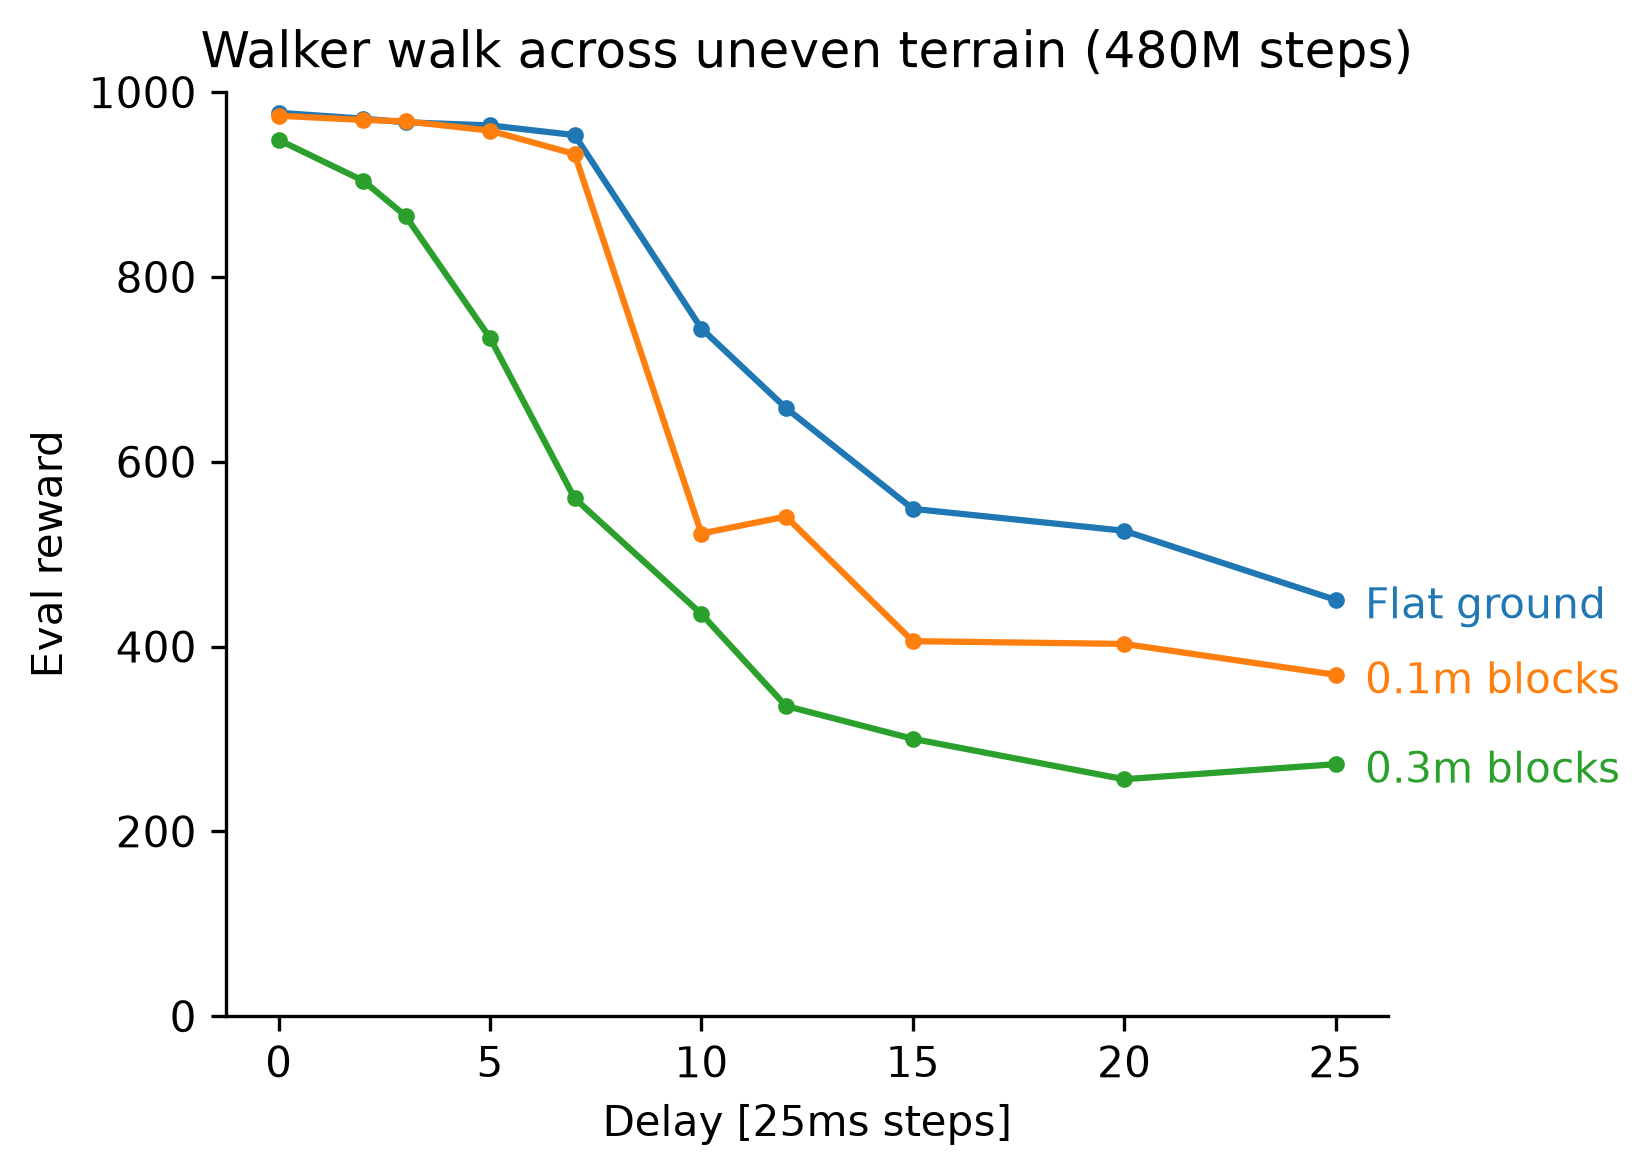

In [34]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[data.condition.isin(["flat_ground", "terrain_blind"])]
for i, h in enumerate((0, 0.1, 0.3)):
    dd = d[d.height==h].groupby("delay_k").reward.mean()
    plt.plot(dd.index, dd.values, '.-')
    if h==0:
        plt.text(25.7, dd.values[-1]-20, "Flat ground", color=f"C{i}")
    else:
        plt.text(25.7, dd.values[-1]-20, f"{h}m blocks", color=f"C{i}")
plt.ylabel("Eval reward")
plt.xlabel("Delay [25ms steps]")
plt.title("Walker walk across uneven terrain (480M steps)")
plt.ylim(0, 1000)
sns.despine()

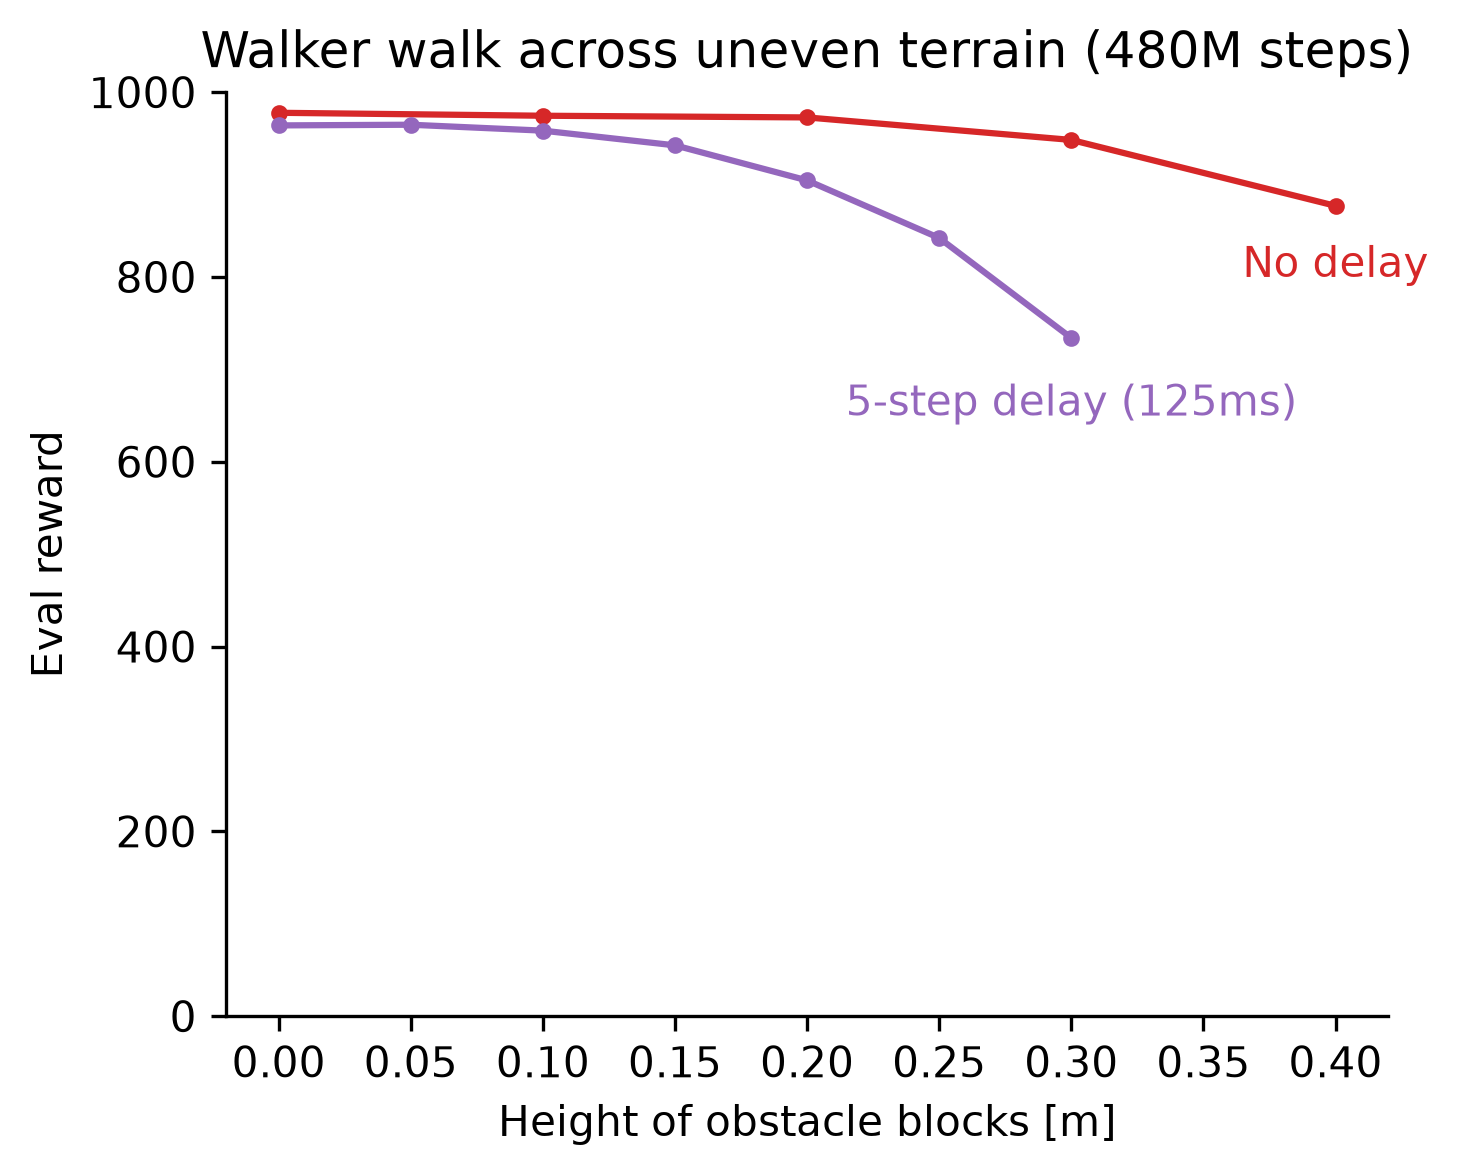

In [47]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[data.condition.isin(["flat_ground", "terrain_blind"])]
for i, delay in enumerate((0, 5)):
    dd = d[d.delay_k==delay].groupby("height").reward.mean()
    plt.plot(dd.index, dd.values, '.-', color=f"C{i+3}")
plt.text(0.40, 800, "No delay", color="C3", ha="center")
plt.text(0.30, 650, "5-step delay (125ms)", color="C4", ha="center")
plt.ylabel("Eval reward")
plt.xlabel("Height of obstacle blocks [m]")
plt.title("Walker walk across uneven terrain (480M steps)")
plt.ylim(0, 1000)
sns.despine()

In [60]:
long_d = pd.read_csv("long_curves.csv")
long_d = long_d[long_d.delay_k==5]

In [54]:
long_d

,wandb_id,condition,delay_k,height,seed_pair,budget,step,reward
0,qt2rwbr3,flat_ground,5,0.0,i43/p12345,1000000000,737280,28.015682
1,qt2rwbr3,flat_ground,5,0.0,i43/p12345,1000000000,1228800,41.385933
2,qt2rwbr3,flat_ground,5,0.0,i43/p12345,1000000000,1966080,41.237518
3,qt2rwbr3,flat_ground,5,0.0,i43/p12345,1000000000,2457600,42.933510
4,qt2rwbr3,flat_ground,5,0.0,i43/p12345,1000000000,3194880,104.114944
...,...,...,...,...,...,...,...,...
3953,sog4k5xi,terrain_blind,5,0.3,i43/p43,2000000000,1977630720,887.851257
3954,sog4k5xi,terrain_blind,5,0.3,i43/p43,2000000000,1982545920,888.266541
3955,sog4k5xi,terrain_blind,5,0.3,i43/p43,2000000000,1987215360,889.488770
3956,sog4k5xi,terrain_blind,5,0.3,i43/p43,2000000000,1992130560,879.971680


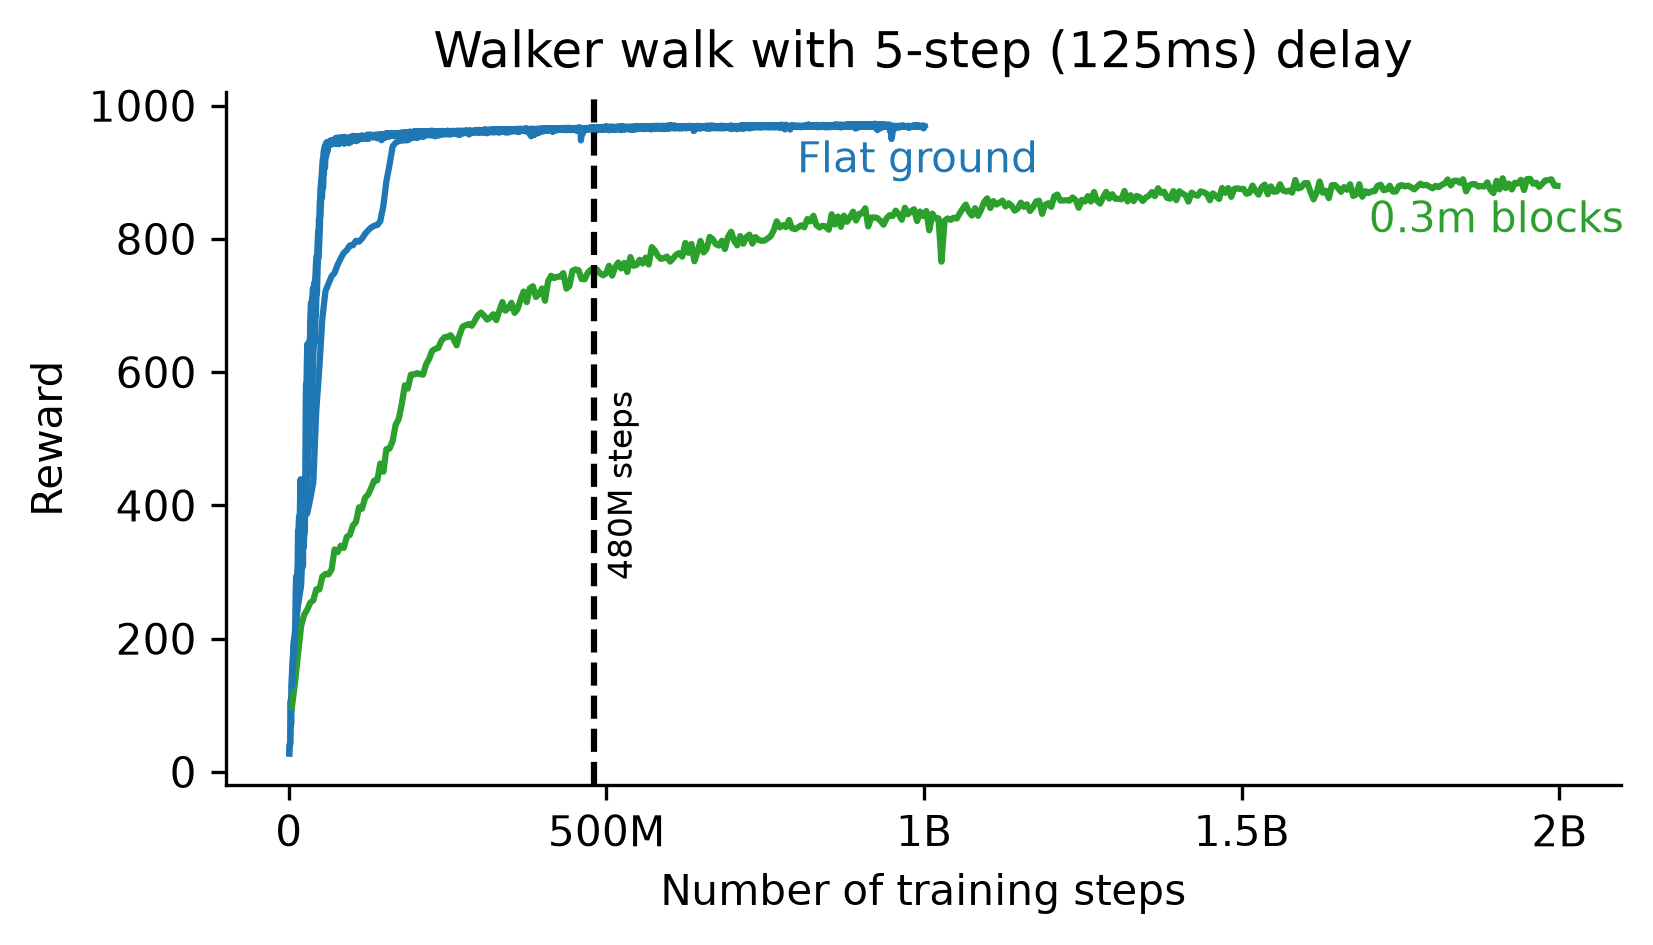

In [69]:
plt.figure(figsize=(6, 3), dpi=300)
for (wandb_id, g) in long_d.groupby("wandb_id"):
    c = "C0" if g.condition.iloc[0] == "flat_ground" else "C2"
    plt.plot(g.step, g.reward, color=c)
plt.axvline(4.8e8, color="k", ls="--")
plt.text(5e8, 300, "480M steps",fontsize=8, rotation=90)
plt.xticks([0, 5e8, 1e9, 1.5e9, 2.0e9], [0, "500M", "1B", "1.5B", "2B"])
plt.xlabel("Number of training steps")
plt.ylabel("Reward")
plt.text(8e8, 900, "Flat ground", color="C0")
plt.text(17e8, 810, "0.3m blocks", color="C2")
plt.title("Walker walk with 5-step (125ms) delay")
sns.despine()

In [112]:
factors_list = ["efference", "forward_model", "block_sensor", "privileged_critic", "servo"]
factors = pd.read_csv("factors.csv")
factors["block_sensor"] = np.logical_not(factors.blind)
subset = factors[["wandb_id"] + factors_list + ["reward_480M"]]
subset = subset.groupby(factors_list).reward_480M.agg(["mean", "std"]).reset_index()

In [125]:
subset

,efference,forward_model,block_sensor,privileged_critic,servo,mean,std
0,False,False,False,False,False,NaN,NaN
1,False,False,False,True,False,703.618243,NaN
2,False,False,False,True,True,667.862457,NaN
3,False,True,False,True,False,771.465393,NaN
4,False,True,False,True,True,812.173334,NaN
5,True,False,False,False,False,NaN,NaN
6,True,False,False,True,False,733.968663,13.722739
7,True,False,False,True,True,789.216699,NaN
8,True,False,True,True,False,727.493158,NaN
9,True,True,False,True,False,NaN,NaN


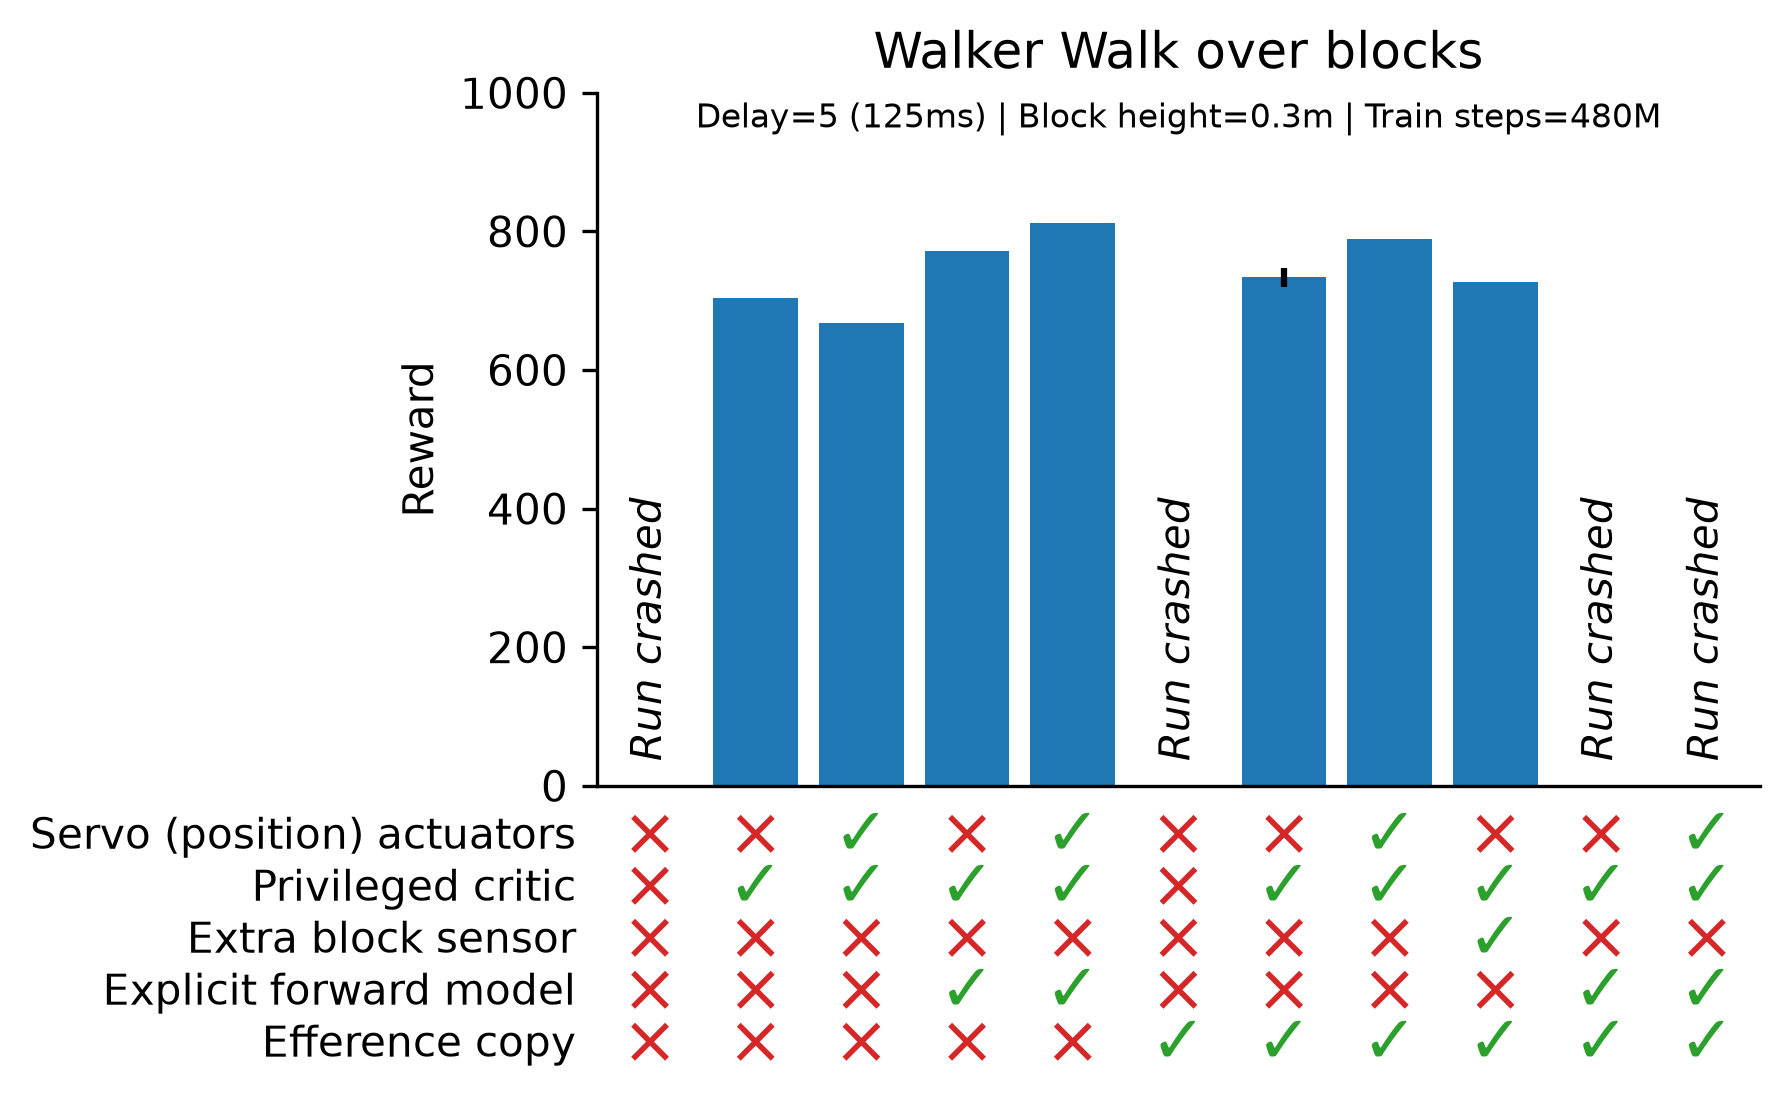

In [138]:
plt.figure(figsize=(5, 3), dpi=300)
plt.bar(subset.index, subset["mean"])
plt.errorbar(subset.index, subset["mean"], subset["std"], fmt="none", color="k")
for i in subset.index:
    for j, f in enumerate(factors_list):
        if subset[f].iloc[i]:
            plt.text(i, j*75 - 75*5, "$\\checkmark$", color="C2", ha="center", va="center", fontsize=16)
        else:
            plt.text(i, j*75 - 75*5, "$\\times$", color="C3", ha="center", va="center", fontsize=16)
    if not np.isfinite(subset["mean"].iloc[i]):
        plt.text(i, 50, "Run crashed", rotation=90, ha="center", style="italic")
for j, f in enumerate(["Efference copy", "Explicit forward model", "Extra block sensor",
                       "Privileged critic", "Servo (position) actuators"]):
    plt.text(-0.7, j*75 - 75*5, f, color="k", ha="right", va="center")#, fontsize=11)
plt.xticks([])
plt.ylim(0, 1000)
plt.ylabel("Reward")
plt.xlim(-0.5, 10.5)
plt.title("Walker Walk over blocks")
plt.text(5, 950, "Delay=5 (125ms) | Block height=0.3m | Train steps=480M", ha="center",fontsize=8)
sns.despine()
#plt.ylim(0, 7)

In [140]:
factors = pd.read_csv("factors.csv")
factors["block_sensor"] = np.logical_not(factors.blind)
factors[["wandb_id"] + factors_list + ["reward_480M"]]

,wandb_id,efference,forward_model,block_sensor,privileged_critic,servo,reward_480M
0,i5dr3ysp,True,False,False,True,False,718.457898
1,77va16yb,True,False,False,True,False,738.917676
2,sog4k5xi,True,False,False,True,False,744.530414
3,u8xdfjid,True,False,False,True,True,789.216699
4,tsmtpb80,True,False,False,False,False,NaN
5,d7ytv3fx,True,False,True,True,False,727.493158
6,loaln8fh,True,True,False,True,False,NaN
7,jxeblbis,True,True,False,True,True,NaN
8,oljpt79a,False,False,False,True,False,703.618243
9,es8cg6rj,False,False,False,True,True,667.862457
